# So sánh động tác bằng Dynamic Time Warping (DTW)

Notebook này tạo baseline để so sánh **chuỗi góc khớp của video mẫu và video người chơi**.

## Đầu vào
- `joint_angles_filtered.csv`: góc khớp video mẫu đã preprocess/lọc.
- Một file góc khớp thứ hai cho video người chơi, ví dụ `player_joint_angles_filtered.csv`.

Hai file cần có các cột góc chung như `left_elbow`, `right_elbow`, `left_knee`, `right_knee`. Nếu chưa có file góc của người chơi, notebook vẫn chạy phần kiểm tra dữ liệu mẫu, nhưng chưa thể tính điểm so sánh.

**Lưu ý:** DTW căn chỉnh tốc độ khác nhau; nó không tự đảm bảo hai video dùng cùng hệ tọa độ hoặc cùng góc nhìn. Hãy trích xuất góc bằng cùng một pipeline cho cả hai video.

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

BASE_DIR = Path.cwd()

REFERENCE_PATH = BASE_DIR / "joint_angles_filtered.csv"
PLAYER_PATH = BASE_DIR / "joint_angles_student.csv"

JOINTS = [
    "left_elbow",
    "right_elbow",
    "left_knee",
    "right_knee",
]

# DTW có thể tốn thời gian O(N*M); với video dài, giới hạn cửa sổ
# giúp tránh các căn chỉnh quá xa nhau về thời gian.
SAKOE_CHIBA_RADIUS = 30

if not REFERENCE_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy {REFERENCE_PATH}. "
        "Sửa REFERENCE_PATH thành file góc khớp mẫu thực tế."
    )

reference = pd.read_csv(REFERENCE_PATH)
print("Đã đọc video mẫu:", REFERENCE_PATH.name)
print("Số frame mẫu:", len(reference))
display(reference.head())

Đã đọc video mẫu: joint_angles_filtered.csv
Số frame mẫu: 368


,frame,timestamp_ms,left_elbow,right_elbow,left_shoulder,right_shoulder,left_knee,right_knee
0,0,0.0,131.427522,132.534679,75.454200,64.042210,83.544904,82.828975
1,1,33.0,128.416507,131.538772,78.323327,66.242285,81.752927,85.965359
2,2,66.0,126.519608,131.302969,78.447531,66.269076,79.425099,86.521536
3,3,100.0,125.908328,131.848869,75.888071,64.104454,76.690882,84.435791
4,4,133.0,125.829454,133.005710,70.627730,59.556430,74.389458,82.157250


## 1. Chuẩn hóa chuỗi góc

Mỗi frame được biểu diễn bằng vector góc khớp. Vì các góc đều cùng đơn vị độ, ta dùng độ lệch góc trung bình bình phương làm khoảng cách frame-to-frame. Frame có giá trị thiếu sẽ bị loại khỏi chuỗi ở baseline này; sau đó có thể nâng cấp để xử lý mask thiếu rõ ràng.

In [8]:
def prepare_sequence(df, joints):
    missing = [col for col in joints if col not in df.columns]
    if missing:
        raise ValueError(f"Thiếu cột góc khớp: {missing}")

    data = df[joints].apply(pd.to_numeric, errors="coerce")
    # Không để DTW nhận NaN/inf.
    data = data.replace([np.inf, -np.inf], np.nan).dropna(axis=0, how="any")

    if len(data) == 0:
        raise ValueError("Không còn frame hợp lệ sau khi loại NaN/inf.")

    return data.to_numpy(dtype=float), data.index.to_numpy()

reference_seq, reference_rows = prepare_sequence(reference, JOINTS)

print("Các khớp dùng:", JOINTS)
print("Frame hợp lệ của video mẫu:", len(reference_seq))
print("Khoảng giá trị góc mẫu:")
display(reference[JOINTS].describe().round(2))

Các khớp dùng: ['left_elbow', 'right_elbow', 'left_knee', 'right_knee']
Frame hợp lệ của video mẫu: 190
Khoảng giá trị góc mẫu:


,left_elbow,right_elbow,left_knee,right_knee
count,251.00,190.00,368.00,368.00
mean,133.70,143.28,75.59,70.09
std,26.03,20.70,35.17,32.17
min,26.16,67.27,17.25,15.58
25%,125.71,132.79,48.36,45.48
50%,137.17,146.77,67.92,63.50
75%,150.64,156.74,97.00,87.33
max,177.41,178.80,169.31,177.24


## 2. Kiểm tra file người chơi

Nếu đã có file góc của video người chơi, đặt tên `player_joint_angles_filtered.csv` trong cùng thư mục và chạy cell dưới. Nếu chưa có, hãy chạy tiếp các cell về thuật toán DTW để chuẩn bị; phần tính điểm sẽ chạy sau khi có file thứ hai.

In [9]:
player_available = PLAYER_PATH.exists()

if player_available:
    player = pd.read_csv(PLAYER_PATH)
    player_seq, player_rows = prepare_sequence(player, JOINTS)
    print("Đã đọc video người chơi:", PLAYER_PATH.name)
    print("Frame hợp lệ của người chơi:", len(player_seq))
    display(player.head())
else:
    player = None
    player_seq = None
    player_rows = None
    print(
        f"Chưa có {PLAYER_PATH.name}. "
        "Chưa thể tính điểm so sánh; cần trích xuất video người chơi qua cùng pipeline."
    )

Đã đọc video người chơi: joint_angles_student.csv
Frame hợp lệ của người chơi: 154


,frame,timestamp_ms,left_elbow,right_elbow,left_shoulder,right_shoulder,left_knee,right_knee
0,0,0.0,134.253713,149.531885,60.227705,31.539746,115.869330,121.689406
1,1,33.0,134.379491,148.627808,65.281071,33.386293,107.106835,125.076927
2,2,66.0,134.426887,148.071748,69.079181,34.729234,103.026285,126.310097
3,3,100.0,134.419025,147.947760,71.465105,35.511155,103.105763,125.331720
4,4,133.0,133.148633,147.966827,72.035380,35.861308,108.921176,122.180276


## 3. Cài đặt DTW có cửa sổ Sakoe–Chiba

Khoảng cách giữa hai frame là căn bậc hai của trung bình bình phương chênh lệch góc trên các khớp đã chọn. DTW tìm đường căn chỉnh có tổng chi phí nhỏ nhất, đồng thời giới hạn độ lệch thời gian bằng cửa sổ Sakoe–Chiba.

Độ phức tạp cơ bản là O(N×M); cửa sổ giúp hạn chế căn chỉnh lệch quá xa. `SAKOE_CHIBA_RADIUS` được tính theo số frame, nên cần điều chỉnh nếu FPS hoặc độ dài video khác nhiều.

In [10]:
def frame_distance(a, b):
    # RMSE giữa vector góc của hai frame
    return float(np.sqrt(np.mean((a - b) ** 2)))


def dtw_distance(seq_a, seq_b, radius=30):
    n, m = len(seq_a), len(seq_b)

    if n == 0 or m == 0:
        raise ValueError("Chuỗi đầu vào không được rỗng.")

    # Nếu độ dài chênh quá lớn, nới radius tối thiểu để có đường đi khả thi.
    radius = max(int(radius), abs(n - m))

    cost = np.full((n + 1, m + 1), np.inf, dtype=float)
    length = np.zeros((n + 1, m + 1), dtype=np.int32)
    cost[0, 0] = 0.0

    for i in range(1, n + 1):
        j_start = max(1, i - radius)
        j_end = min(m, i + radius)

        for j in range(j_start, j_end + 1):
            d = frame_distance(seq_a[i - 1], seq_b[j - 1])

            candidates = (
                cost[i - 1, j],      # đi dọc
                cost[i, j - 1],      # đi ngang
                cost[i - 1, j - 1],  # đi chéo
            )
            k = int(np.argmin(candidates))
            pi, pj = ((i - 1, j), (i, j - 1), (i - 1, j - 1))[k]

            cost[i, j] = d + cost[pi, pj]
            length[i, j] = length[pi, pj] + 1

    if not np.isfinite(cost[n, m]) or length[n, m] == 0:
        raise ValueError("Không tìm được đường DTW; hãy tăng radius.")

    total_cost = cost[n, m]
    path_length = int(length[n, m])
    return total_cost, total_cost / path_length, path_length


print("Hàm DTW đã sẵn sàng.")

Hàm DTW đã sẵn sàng.


## 4. Tính khoảng cách và điểm baseline

Khoảng cách DTW càng thấp nghĩa là chuỗi góc càng giống nhau theo metric đã chọn. Để có điểm dễ đọc từ 0–100, ta dùng phép biến đổi `100 × exp(-distance / scale)`. Đây chỉ là **điểm baseline**, chưa phải thang điểm đã được hiệu chuẩn bằng dữ liệu người thật; `scale` cần được hiệu chỉnh từ các ví dụ đúng/sai.

In [11]:
if player_seq is None:
    print("Bỏ qua tính điểm vì chưa có file góc khớp của người chơi.")
else:
    total_cost, mean_cost, path_length = dtw_distance(
        reference_seq,
        player_seq,
        radius=SAKOE_CHIBA_RADIUS
    )

    # Tham số scale tạm thời; cần hiệu chuẩn sau khi có các video mẫu.
    SCORE_SCALE = 35.0
    baseline_score = 100.0 * np.exp(-mean_cost / SCORE_SCALE)

    print(f"DTW total cost: {total_cost:.2f}")
    print(f"DTW mean cost (RMSE/frame): {mean_cost:.2f} độ")
    print(f"Độ dài đường căn chỉnh: {path_length} cặp frame")
    print(f"Điểm baseline: {baseline_score:.1f}/100")
    print("Lưu ý: điểm này chưa được hiệu chuẩn, chưa nên dùng làm điểm đánh giá chính thức.")

DTW total cost: 3926.28
DTW mean cost (RMSE/frame): 18.52 độ
Độ dài đường căn chỉnh: 212 cặp frame
Điểm baseline: 58.9/100
Lưu ý: điểm này chưa được hiệu chuẩn, chưa nên dùng làm điểm đánh giá chính thức.


## 5. So sánh trực quan các chuỗi góc

Biểu đồ này hiển thị chuỗi góc trước căn chỉnh theo thời gian. DTW có thể căn chỉnh hai chuỗi khi chúng có tốc độ khác nhau, nhưng ta vẫn cần xem riêng từng khớp và kiểm tra các đoạn thiếu dữ liệu.

Đã lưu: d:\Danceup\DanceUp_App\python\dtw_angle_comparison.png


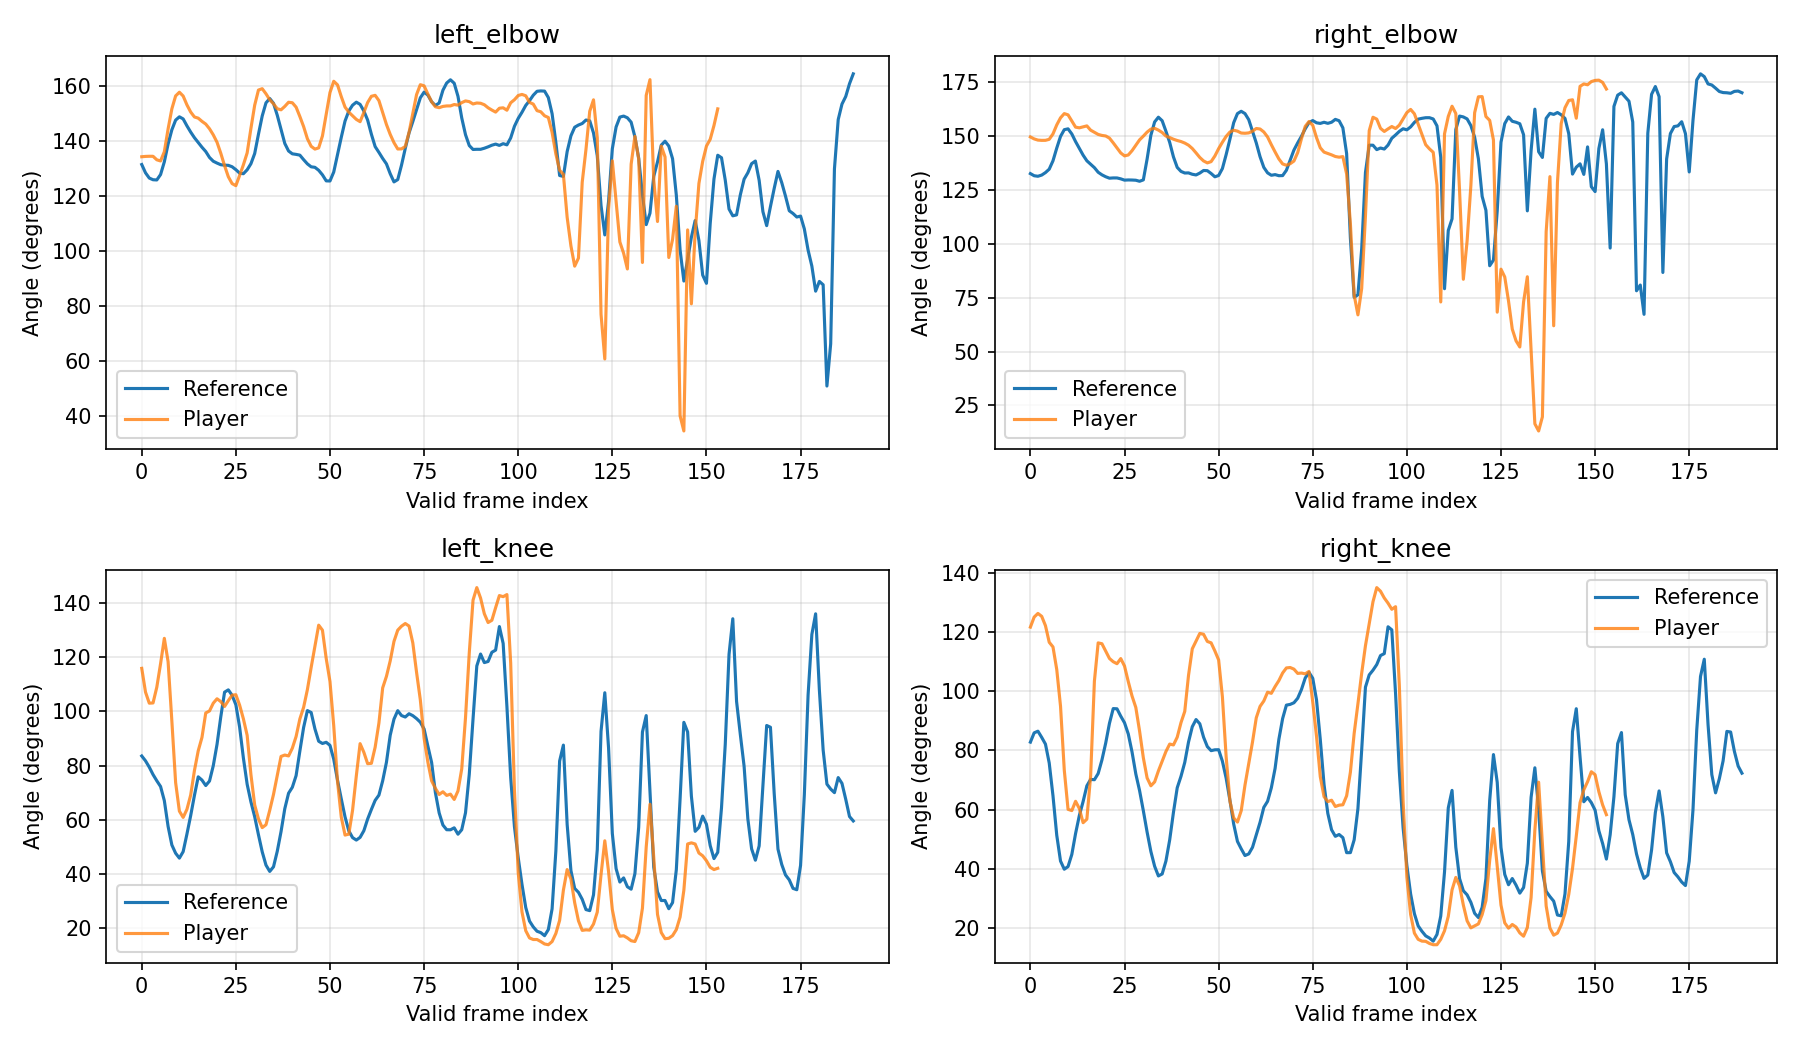

In [12]:
if player_seq is None:
    print("Chưa có chuỗi người chơi để vẽ so sánh.")
else:
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=False)
    axes = axes.ravel()

    for i, joint in enumerate(JOINTS):
        axes[i].plot(np.arange(len(reference_seq)), reference_seq[:, i], label="Reference")
        axes[i].plot(np.arange(len(player_seq)), player_seq[:, i], label="Player", alpha=0.8)
        axes[i].set_title(joint)
        axes[i].set_xlabel("Valid frame index")
        axes[i].set_ylabel("Angle (degrees)")
        axes[i].grid(True, alpha=0.3)
        axes[i].legend()

    fig.tight_layout()
    output_path = BASE_DIR / "dtw_angle_comparison.png"
    fig.savefig(output_path, dpi=150)
    plt.close(fig)
    print("Đã lưu:", output_path)
    display(Image(filename=str(output_path)))

## Tiếp theo

1. Trích xuất video người chơi bằng cùng pipeline với video mẫu.
2. Chạy notebook này và kiểm tra điểm/kết quả từng khớp.
3. Khi có nhiều ví dụ, hiệu chuẩn `SCORE_SCALE`, chọn ngưỡng điểm, rồi mới xây dựng điểm tổng hợp và điểm theo vùng cơ thể.
4. Sau baseline, có thể thêm đường căn chỉnh DTW để giải thích frame nào khớp với frame nào.

**Hạn chế của baseline:** chỉ dùng 4 góc khuỷu tay và đầu gối; chưa xử lý góc vai, độ tin cậy landmark, chuẩn hóa khác biệt cơ thể, góc nhìn camera, hoặc phân biệt động tác đúng về hình dạng nhưng sai thứ tự.